In [1]:
# ==========================================
# ЧАСТЬ 1: ИМПОРТ БИБЛИОТЕК И СОЗДАНИЕ ДАННЫХ
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Импортируем инструменты машинного обучения из Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Настраиваем красивый стиль для будущих графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Фиксируем случайность, чтобы при каждом запуске цифры были одинаковыми
np.random.seed(42)
n_samples = 3000

# Генерируем характеристики клиентов (возраст, чек, обращения в поддержку)
customer_id = np.arange(10001, 10001 + n_samples)
age = np.random.randint(18, 65, size=n_samples)
months_active = np.random.randint(1, 60, size=n_samples)
support_calls = np.random.poisson(lam=2, size=n_samples)
avg_bill = np.random.normal(loc=3500, scale=1200, size=n_samples).round(2)
avg_bill = np.clip(avg_bill, 500, 10000) # Ограничиваем чеки разумными рамками

# Закладываем математическую логику оттока для ИИ
# Если клиент часто звонит в поддержку и у него маленький чек -> он скорее уйдет
churn_score = support_calls * 0.5 - (avg_bill / 2500) + (age / 40) - 2.0
prob = 1 / (1 + np.exp(-churn_score)) # Переводим в вероятность (сигмоида)
churn = np.random.binomial(1, prob)   # Получаем статус (0 - остался, 1 - ушел)

# Собираем все сгенерированные массивы в одну таблицу DataFrame
df = pd.DataFrame({
    'CustomerID': customer_id,
    'Age': age,
    'MonthsActive': months_active,
    'AvgBill': avg_bill,
    'SupportCalls': support_calls,
    'Churn': churn
})

# Выводим первые 5 строк таблицы на экран, чтобы убедиться, что всё создалось успешно
print("=== ТЕСТОВАЯ ВЫГРУЗКА ДАННЫХ (ПЕРВЫЕ 5 СТРОК) ===")
print(df.head())


=== ТЕСТОВАЯ ВЫГРУЗКА ДАННЫХ (ПЕРВЫЕ 5 СТРОК) ===
   CustomerID  Age  MonthsActive  AvgBill  SupportCalls  Churn
0       10001   56             6  4254.00             2      0
1       10002   46            34  3928.59             2      0
2       10003   32             1  1966.88             0      0
3       10004   60            10  5392.85             3      0
4       10005   25            21  2589.80             1      0


=== ПРОВЕРКА НА НАЛИЧИЕ ПУСТЫХ КЛЕТОК (ПРОПУСКОВ) ===
CustomerID      0
Age             0
MonthsActive    0
AvgBill         0
SupportCalls    0
Churn           0
dtype: int64

=== СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ ДАТАСЕТА ===
       CustomerID      Age  MonthsActive  AvgBill  SupportCalls    Churn
count     3000.00  3000.00       3000.00  3000.00       3000.00  3000.00
mean     11500.50    41.15         30.46  3479.31          1.97     0.24
std        866.17    13.47         17.07  1197.76          1.37     0.43
min      10001.00    18.00          1.00   500.00          0.00     0.00
25%      10750.75    30.00         16.00  2663.90          1.00     0.00
50%      11500.50    41.00         30.00  3476.80          2.00     0.00
75%      12250.25    53.00         45.00  4293.02          3.00     0.00
max      13000.00    64.00         59.00  7224.06          8.00     1.00


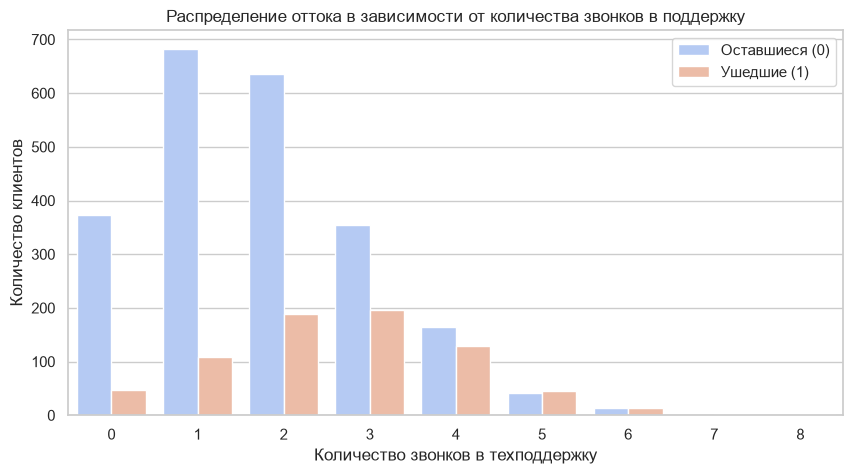

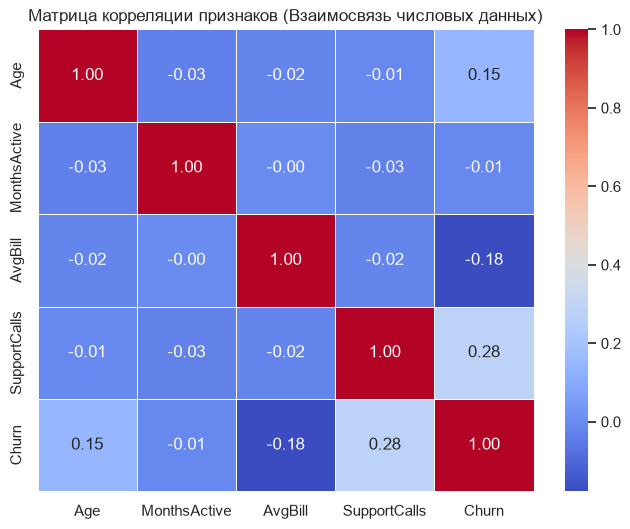

In [2]:
# ==========================================
# ЧАСТЬ 2: АНАЛИЗ И ВИЗУАЛИЗАЦИЯ (EDA)
# ==========================================

print("=== ПРОВЕРКА НА НАЛИЧИЕ ПУСТЫХ КЛЕТОК (ПРОПУСКОВ) ===")
print(df.isnull().sum())
print("\n=== СТАТИСТИЧЕСКИЕ ПОКАЗАТЕЛИ ДАТАСЕТА ===")
print(df.describe().round(2))

# Строим График №1: Зависимость оттока от звонков в поддержку
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='SupportCalls', hue='Churn', palette='coolwarm')
plt.title('Распределение оттока в зависимости от количества звонков в поддержку')
plt.xlabel('Количество звонков в техподдержку')
plt.ylabel('Количество клиентов')
plt.legend(['Оставшиеся (0)', 'Ушедшие (1)'])
plt.show()

# Строим График №2: Матрица взаимной корреляции признаков
plt.figure(figsize=(8, 6))
# Удаляем ID клиента, так как это просто порядковый номер
sns.heatmap(df.drop('CustomerID', axis=1).corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляции признаков (Взаимосвязь числовых данных)')
plt.show()

In [3]:
# ==========================================
# ЧАСТЬ 3: ПОДГОТОВКА И ОБУЧЕНИЕ МОДЕЛИ
# ==========================================

# Разделяем таблицу: X - это факторы, y - то, что предсказываем (Churn)
# Удаляем CustomerID, так как номер договора не влияет на уход человека
X = df.drop(['CustomerID', 'Churn'], axis=1)
y = df['Churn']

# Делим данные в пропорции 80% на обучение и 20% на проверку точности
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Размер обучающей выборки: {X_train.shape} строк")
print(f"Размер тестовой выборки: {X_test.shape} строк\n")

# Инициализируем алгоритм машинного обучения Random Forest (Случайный лес)
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Запускаем процесс обучения ИИ на наших 80% данных
print("Старт обучения модели...")
model.fit(X_train, y_train)
print("Модель успешно обучена!")

Размер обучающей выборки: (2400, 4) строк
Размер тестовой выборки: (600, 4) строк

Старт обучения модели...
Модель успешно обучена!


Общая точность модели (Accuracy): 73.83%

=== ДЕТАЛЬНЫЙ ОТЧЕТ ПО МЕТРИКАМ КЛАССИФИКАЦИИ ===
              precision    recall  f1-score   support

           0       0.78      0.90      0.84       453
           1       0.44      0.24      0.31       147

    accuracy                           0.74       600
   macro avg       0.61      0.57      0.57       600
weighted avg       0.70      0.74      0.71       600



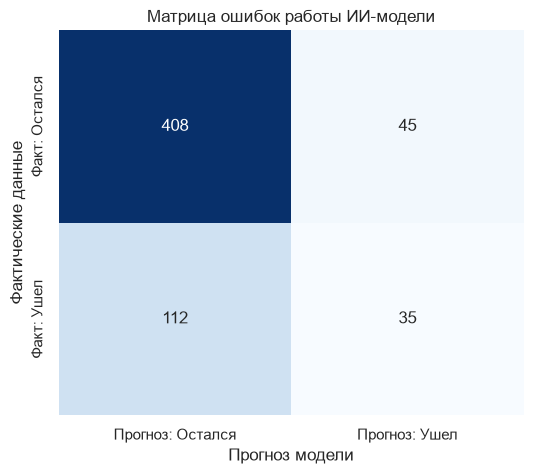

=== ВАЖНОСТЬ ПРИЗНАКОВ ДЛЯ МОДЕЛИ (ЧТО ВЛИЯЕТ СИЛЬНЕЕ ВСЕГО) ===
AvgBill         0.369732
MonthsActive    0.253906
Age             0.245213
SupportCalls    0.131149
dtype: float64


In [4]:
# ==========================================
# ЧАСТЬ 4: ПРОВЕРКА ТОЧНОСТИ И МЕТРИКИ
# ==========================================

# Просим обученную модель сделать предсказания для тестовых 20% клиентов
y_pred = model.predict(X_test)

# Считаем общую точность предсказаний
accuracy = accuracy_score(y_test, y_pred)
print(f"Общая точность модели (Accuracy): {accuracy * 100:.2f}%\n")

# Выводим отчет по метрикам Precision, Recall и F1-score
print("=== ДЕТАЛЬНЫЙ ОТЧЕТ ПО МЕТРИКАМ КЛАССИФИКАЦИИ ===")
print(classification_report(y_test, y_pred))

# Строим График №3: Матрица ошибок (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Прогноз: Остался', 'Прогноз: Ушел'],
            yticklabels=['Факт: Остался', 'Факт: Ушел'])
plt.title('Матрица ошибок работы ИИ-модели')
plt.ylabel('Фактические данные')
plt.xlabel('Прогноз модели')
plt.show()

# Выводим важность признаков (какой фактор сильнее всего влияет на уход клиента)
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("=== ВАЖНОСТЬ ПРИЗНАКОВ ДЛЯ МОДЕЛИ (ЧТО ВЛИЯЕТ СИЛЬНЕЕ ВСЕГО) ===")
print(importances)
